# This is a sample Jupyter Notebook

Below is an example of a code cell. 
Put your cursor into the cell and press Shift+Enter to execute it and select the next one, or click 'Run Cell' button.

Press Double Shift to search everywhere for classes, files, tool windows, actions, and settings.

To learn more about Jupyter Notebooks in PyCharm, see [help](https://www.jetbrains.com/help/pycharm/ipython-notebook-support.html).
For an overview of PyCharm, go to Help → Learn IDE features or refer to [our documentation](https://www.jetbrains.com/help/pycharm/getting-started.html).

In [37]:
%load_ext autoreload
%autoreload 2
# these make it so that if you change the files you import you won't need to restart the Jupyter Notebook kernel

from analytic_formulation import Q_

# --- Params ---
params = {
    'rd':      Q_(0.316, 'm'),
    'nP':      Q_(4000, 'rpm'),
    'a':       1.2,
    'b':       1.0,
    'c':       0.5,
    'PP':      Q_(100.0, 'kW'),
    'mv':      Q_(1500.0, 'kg'),
    'g':       Q_(9.81, 'm/s**2'),
    'fr':      0.015,                    # plain float, avoids pint friction
    'rho_a':   Q_(1.225, 'kg/m**3'),
    'CD':      0.30,                     # plain float
    'Af':      Q_(2.2, 'm**2'),
    'gamma_m': 1.05,                     # plain float
    'eta_T':   0.92,                     # plain float
    'eta_o':   0.38,
    'HL':      Q_(44e6, 'J/kg'),
}



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload





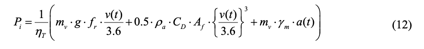

In [41]:
from scipy.optimize import minimize
from analytic_formulation import OlengEquations, Q_

delta_s    = Q_(500.0, 'm')
total_dist = Q_(5_000.0, 'm')
n_steps    = int(total_dist / delta_s)
v_cruise   = Q_(90, 'km/h').to('m/s')
v_initial = Q_(0.1, 'm/s')

# Use a dedicated model starting at cruise speed so the optimizer has a meaningful baseline
model_opt = OlengEquations(params, initial_velocity=v_cruise)

initial_guess = [0.0 for _ in range(n_steps)]


def fuel_objective(acceleration_profile):
    results = model_opt.run(acceleration_profile, delta_s, xi_ax=3.9)

    total_fuel = results['fuel_cumulative_kg'].iloc[-1]

    return total_fuel


minimization = minimize(fuel_objective, initial_guess, method='Nelder-Mead')

print(fuel_objective(minimization.x))
print(minimization)


0.0
       message: Optimization terminated successfully.
       success: True
        status: 0
           fun: 0.0
             x: [ 9.892e-01  1.140e-01  6.894e-01  6.237e-01  3.908e-01
                 -1.119e+00  5.973e-02  3.121e-01 -8.645e-01 -2.125e+00]
           nit: 178
          nfev: 395
 final_simplex: (array([[ 9.892e-01,  1.140e-01, ..., -8.645e-01,
                        -2.125e+00],
                       [ 9.892e-01,  1.140e-01, ..., -8.644e-01,
                        -2.125e+00],
                       ...,
                       [ 9.891e-01,  1.140e-01, ..., -8.644e-01,
                        -2.125e+00],
                       [ 9.891e-01,  1.140e-01, ..., -8.644e-01,
                        -2.125e+00]], shape=(11, 10)), array([ 0.000e+00,  0.000e+00,  0.000e+00,  0.000e+00,
                        0.000e+00,  0.000e+00,  0.000e+00,  0.000e+00,
                        0.000e+00,  0.000e+00,  0.000e+00]))


Optimal acceleration profile (m/s²):
[ 0.98916519  0.1140139   0.68940009  0.62368322  0.39079736 -1.11898517
  0.05972799  0.31214179 -0.86445374 -2.12470794]


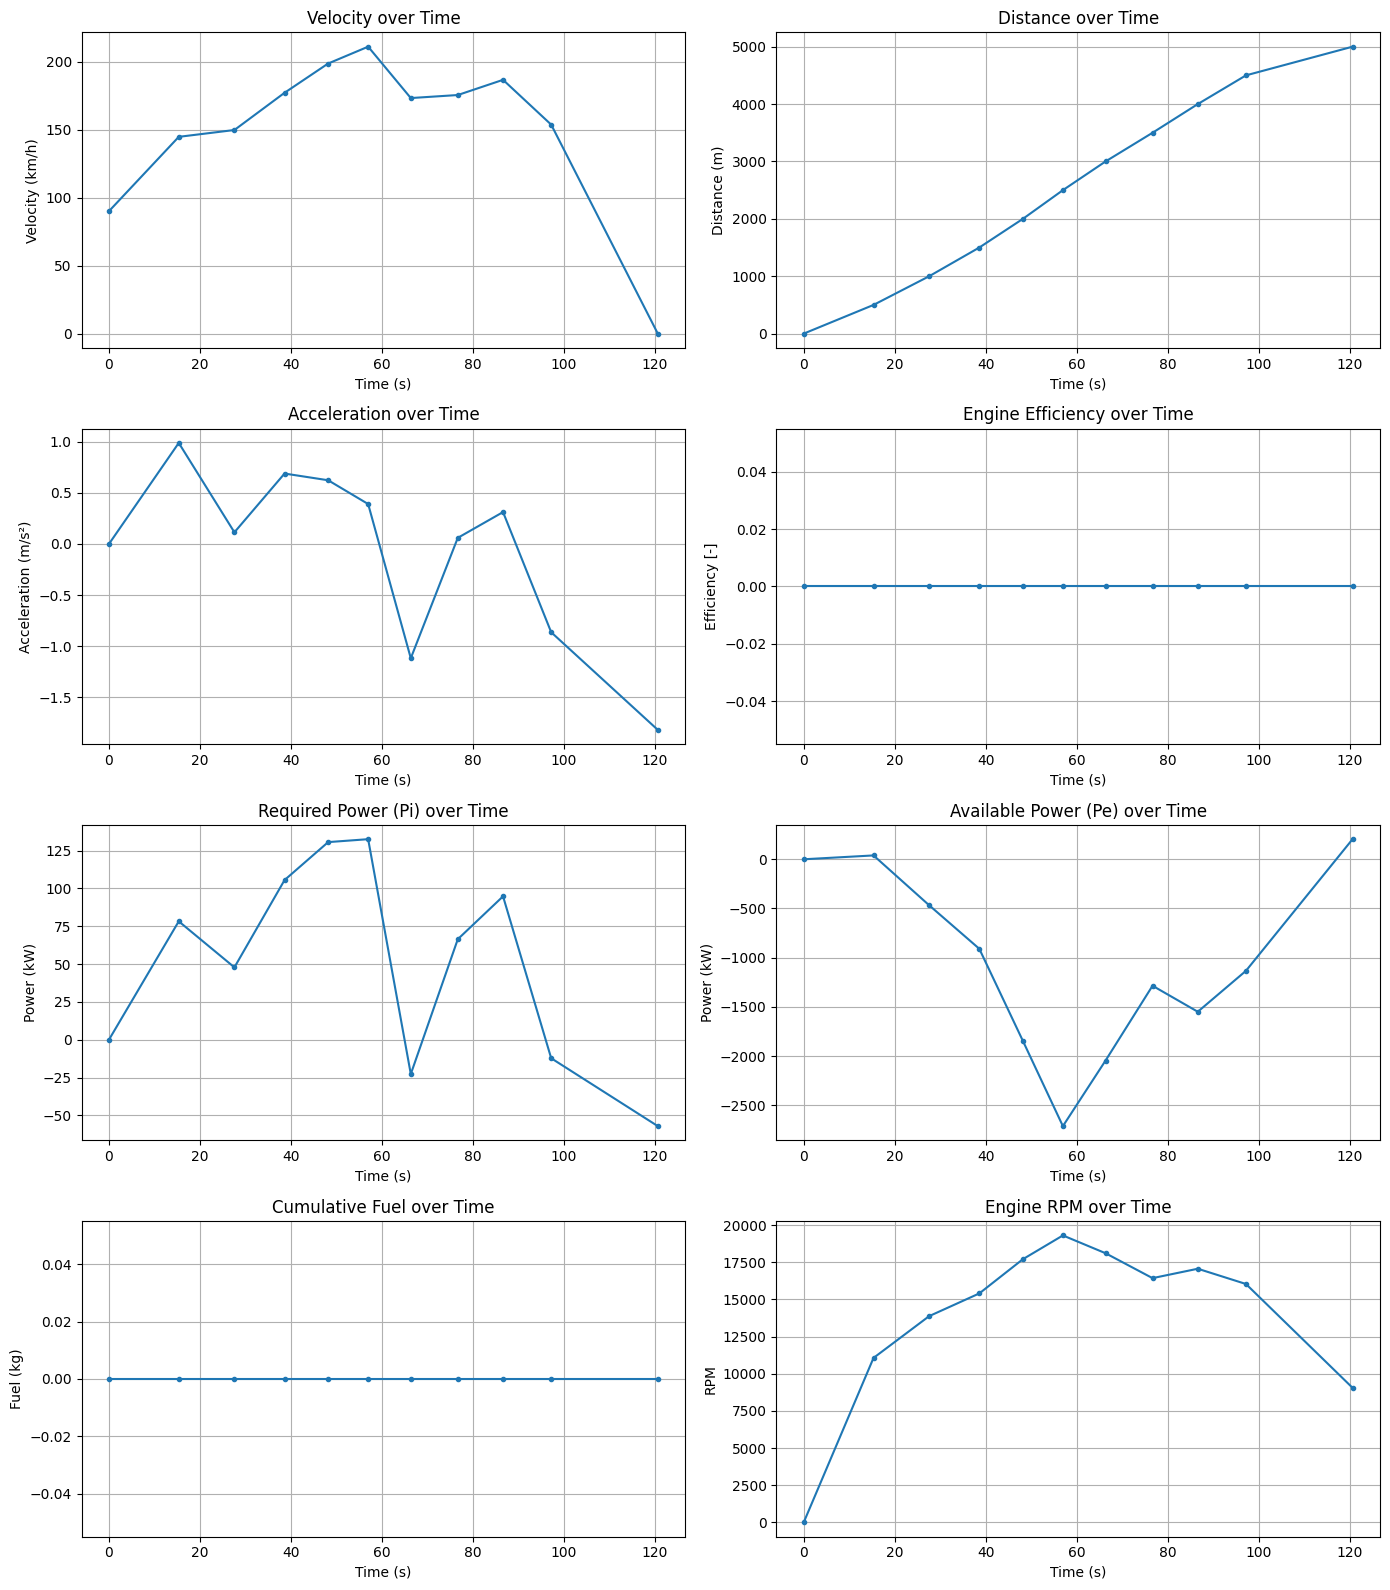

In [46]:
import matplotlib.pyplot as plt

results = model_opt.run(minimization.x, delta_s, xi_ax=3.9, output_path="results.csv")

print("Optimal acceleration profile (m/s²):")
print(minimization.x)

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

plots = [
    ('time_s', 'velocity_ms',          'Time (s)', 'Velocity (km/h)',       'Velocity over Time'),
    ('time_s', 'distance_m',           'Time (s)', 'Distance (m)',          'Distance over Time'),
    ('time_s', 'acceleration_ms2',     'Time (s)', 'Acceleration (m/s²)',   'Acceleration over Time'),
    ('time_s', 'efficiency',           'Time (s)', 'Efficiency [-]',        'Engine Efficiency over Time'),
    ('time_s', 'Pi_kW',               'Time (s)', 'Power (kW)',            'Required Power (Pi) over Time'),
    ('time_s', 'Pe_kW',               'Time (s)', 'Power (kW)',            'Available Power (Pe) over Time'),
    ('time_s', 'fuel_cumulative_kg',   'Time (s)', 'Fuel (kg)',             'Cumulative Fuel over Time'),
    ('time_s', 'engine_rpm',           'Time (s)', 'RPM',                   'Engine RPM over Time'),
]

for ax, (x_col, y_col, x_label, y_label, title) in zip(axes, plots):
    y_data = results[y_col] * 3.6 if y_col == 'velocity_ms' else results[y_col]
    ax.plot(results[x_col], y_data, marker='o', markersize=3)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_title(title)
    ax.grid(True)

plt.tight_layout()
plt.show()